# Beginner A/B Test Project: Did the Ads Work?

**The story:** A company showed ads to most of its users (the **ad group**). It kept a small group
of users who saw a harmless Public Service Announcement (PSA) instead (the **PSA group**, also
called the *control group*). We want to know: **did the ads make more people buy?**

**Words you should know**
- **Conversion:** a user bought something (`converted` = 1) or did not (`converted` = 0).
- **Conversion rate:** the share of users who converted. Example: 2.5% means 25 buyers per 1,000 users.
- **Control group:** the group that did NOT get the new thing (here: the PSA group). It shows what
  would have happened anyway.
- **Null hypothesis (H0):** "the ads made no difference."
- **p-value:** if H0 were true, how likely would it be to see a difference this big just by luck?
  A small p-value (below 0.05) means "unlikely to be luck."
- **Confidence interval (CI):** a range that likely contains the true difference.

**What we will do:** load the data, check it, compare the two groups, run one statistical test,
and write a plain-English conclusion.

**Dataset:** Kaggle "Marketing A/B Testing" (`marketing_AB.csv`).

In [2]:
# Step 0: import the tools we need
import glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportions_ztest   # the statistical test

## Step 1: Load the data
Put `marketing_AB.csv` (or the `.zip`) in the same folder as this notebook.
In Google Colab, run the cell and upload the file when asked.

In [3]:
files_found = glob.glob("marketing_AB*")

if not files_found:
    try:
        from google.colab import files          # only works inside Google Colab
        print("Please upload marketing_AB.csv (or the zip file):")
        files.upload()
        files_found = glob.glob("marketing_AB*")
    except ImportError:
        pass

if not files_found:
    raise FileNotFoundError("Dataset not found. Put marketing_AB.csv next to this notebook.")

df = pd.read_csv(files_found[0])
print("Loaded:", files_found[0])
df.head()

Please upload marketing_AB.csv (or the zip file):


Saving marketing_AB.csv.zip to marketing_AB.csv.zip
Loaded: marketing_AB.csv.zip


,Unnamed: 0,user id,test group,converted,total ads,most ads day,most ads hour
0,0,1069124,ad,False,130,Monday,20
1,1,1119715,ad,False,93,Tuesday,22
2,2,1144181,ad,False,21,Tuesday,18
3,3,1435133,ad,False,355,Tuesday,10
4,4,1015700,ad,False,276,Friday,14


## Step 2: Check and clean the data
Before any analysis we always check: how big is the data, is anything missing, any duplicates?

In [4]:
# Tidy the column names: remove the useless index column, replace spaces with underscores
df = df.drop(columns="Unnamed: 0", errors="ignore")
df.columns = df.columns.str.replace(" ", "_")

# 'converted' is True/False. Turn it into 1/0 so we can average it.
df["converted"] = df["converted"].astype(int)

print("Rows and columns:", df.shape)
print("\nMissing values:\n", df.isna().sum())
print("\nDuplicate users:", df["user_id"].duplicated().sum())
print("\nUsers in each group:\n", df["test_group"].value_counts())
df.head()

Rows and columns: (588101, 6)

Missing values:
 user_id          0
test_group       0
converted        0
total_ads        0
most_ads_day     0
most_ads_hour    0
dtype: int64

Duplicate users: 0

Users in each group:
 test_group
ad     564577
psa     23524
Name: count, dtype: int64


,user_id,test_group,converted,total_ads,most_ads_day,most_ads_hour
0,1069124,ad,0,130,Monday,20
1,1119715,ad,0,93,Tuesday,22
2,1144181,ad,0,21,Tuesday,18
3,1435133,ad,0,355,Tuesday,10
4,1015700,ad,0,276,Friday,14


**What we learned:** there are no missing values and no duplicate users, so the data is clean.
The PSA group is much smaller than the ad group (about 4% of users). That is fine, but it means
our estimate for the PSA group will be less precise.

## Step 3: Compare conversion rates
The key number in an A/B test is the conversion rate of each group.

In [5]:
summary = df.groupby("test_group")["converted"].agg(users="count", conversions="sum",
                                                    conversion_rate="mean")
summary

,users,conversions,conversion_rate
test_group,,,
ad,564577,14423,0.025547
psa,23524,420,0.017854


Ad group : 2.55% converted
PSA group: 1.79% converted
Difference: 0.77 percentage points


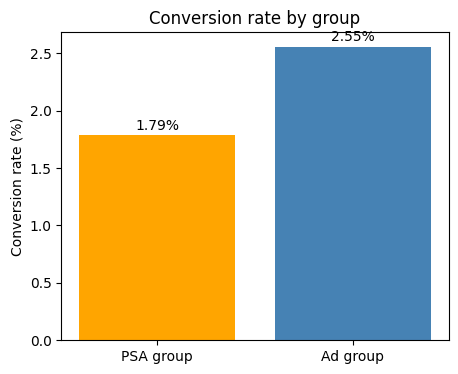

In [6]:
# Save the numbers we will reuse later
users_ad = summary.loc["ad", "users"]
users_psa = summary.loc["psa", "users"]
conv_ad = summary.loc["ad", "conversions"]
conv_psa = summary.loc["psa", "conversions"]
rate_ad = conv_ad / users_ad
rate_psa = conv_psa / users_psa

print(f"Ad group : {rate_ad:.2%} converted")
print(f"PSA group: {rate_psa:.2%} converted")
print(f"Difference: {(rate_ad - rate_psa) * 100:.2f} percentage points")

# A simple bar chart
plt.figure(figsize=(5, 4))
plt.bar(["PSA group", "Ad group"], [rate_psa * 100, rate_ad * 100], color=["orange", "steelblue"])
plt.ylabel("Conversion rate (%)")
plt.title("Conversion rate by group")
for i, r in enumerate([rate_psa, rate_ad]):
    plt.text(i, r * 100 + 0.05, f"{r:.2%}", ha="center")
plt.show()

The ad group converts more. But is this a real effect, or could it be luck? That is what the next
step answers.

## Step 4: Is the difference real? (Hypothesis test)

- **H0 (null hypothesis):** the ads make no difference. Both groups have the same conversion rate.
- **H1 (alternative):** the conversion rates are different.
- We use a **two-proportion z-test**, the standard test for comparing two conversion rates.
- We will say the result is "significant" if the **p-value is below 0.05**.

In [7]:
z_stat, p_value = proportions_ztest(count=[conv_ad, conv_psa], nobs=[users_ad, users_psa])

print(f"z-statistic: {z_stat:.2f}")
print(f"p-value    : {p_value:.2e}")

if p_value < 0.05:
    print("\nResult: p-value is below 0.05, so we REJECT H0.")
    print("The difference is very unlikely to be just luck: the ads seem to increase conversions.")
else:
    print("\nResult: p-value is 0.05 or higher, so we FAIL TO REJECT H0.")
    print("We cannot say the ads made a difference.")

z-statistic: 7.37
p-value    : 1.71e-13

Result: p-value is below 0.05, so we REJECT H0.
The difference is very unlikely to be just luck: the ads seem to increase conversions.


## Step 5: How big is the effect? (Confidence interval)
A p-value only says "there is a difference." Managers want to know **how big**.
A 95% confidence interval gives a likely range for the true difference.

In [8]:
difference = rate_ad - rate_psa

# Standard error of the difference between two proportions
std_error = np.sqrt(rate_ad * (1 - rate_ad) / users_ad + rate_psa * (1 - rate_psa) / users_psa)

ci_low = difference - 1.96 * std_error      # 1.96 is the number for a 95% interval
ci_high = difference + 1.96 * std_error

relative_lift = difference / rate_psa

print(f"Difference: {difference * 100:.2f} percentage points")
print(f"95% confidence interval: {ci_low * 100:.2f} to {ci_high * 100:.2f} percentage points")
print(f"Relative lift: {relative_lift:.0%} more conversions than the PSA group")

Difference: 0.77 percentage points
95% confidence interval: 0.60 to 0.94 percentage points
Relative lift: 43% more conversions than the PSA group


**How to read this:** the interval does not include 0, which agrees with the small p-value. We
are fairly sure the ads really increased the conversion rate, and the true increase is probably
somewhere inside this range.

## Step 6: What does this mean for the business?
The PSA group shows what would have happened *without* ads. So only the **extra** conversions
count as the ads' results.

In [9]:
extra_conversions = users_ad * difference                 # conversions caused by the ads
share_from_ads = extra_conversions / conv_ad              # share of the ad group's conversions

REVENUE_PER_CONVERSION = 50     # ASSUMPTION: not in the data. Change it to test other values.
extra_revenue = extra_conversions * REVENUE_PER_CONVERSION

print(f"Conversions in the ad group     : {conv_ad:,}")
print(f"Extra conversions caused by ads : about {extra_conversions:,.0f}")
print(f"Share of conversions due to ads : about {share_from_ads:.0%} (the rest would happen anyway)")
print(f"Extra revenue (at ${REVENUE_PER_CONVERSION} per conversion): about ${extra_revenue:,.0f}")
print("\nNote: we do not know the campaign cost, so we cannot calculate profit yet.")

Conversions in the ad group     : 14,423
Extra conversions caused by ads : about 4,343
Share of conversions due to ads : about 30% (the rest would happen anyway)
Extra revenue (at $50 per conversion): about $217,149

Note: we do not know the campaign cost, so we cannot calculate profit yet.


## Step 7 (Bonus): Who responded to the ads?
Let's group users by how many ads they saw and compare the two groups.
**Careful:** this is for exploring only. It shows patterns, not proof of cause.

Conversion rate (%) by number of ads seen:
test_group        psa     ad
ads_seen_group              
1-5              0.28   0.25
6-10             0.67   0.49
11-25            1.00   1.02
26-50            2.66   3.54
51-100           5.77  11.63
100+            11.88  17.14


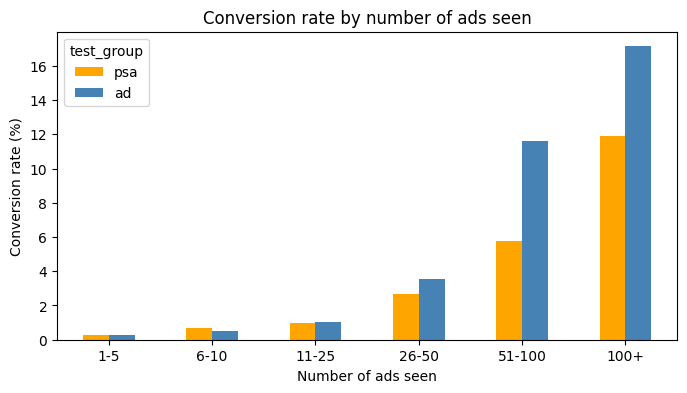

In [10]:
bins = [0, 5, 10, 25, 50, 100, np.inf]
labels = ["1-5", "6-10", "11-25", "26-50", "51-100", "100+"]
df["ads_seen_group"] = pd.cut(df["total_ads"], bins=bins, labels=labels)

by_exposure = df.pivot_table(index="ads_seen_group", columns="test_group",
                             values="converted", aggfunc="mean", observed=False) * 100
by_exposure = by_exposure[["psa", "ad"]].round(2)
print("Conversion rate (%) by number of ads seen:")
print(by_exposure)

by_exposure.plot(kind="bar", figsize=(8, 4), color=["orange", "steelblue"])
plt.ylabel("Conversion rate (%)")
plt.xlabel("Number of ads seen")
plt.title("Conversion rate by number of ads seen")
plt.xticks(rotation=0)
plt.show()

**What we notice:** for users who saw only a few ads (up to about 25), the ad and PSA groups
convert at about the same rate. The big gap appears for users who saw many ads (51 or more).
So the ads seem to work mainly on highly engaged users. We would need a deeper analysis to be
sure.

## Step 8: Conclusion (in plain English)

In [11]:
print(f"""
CONCLUSION
----------
Question: Did the ad campaign increase conversions compared with showing a PSA?

Answer  : Yes. {rate_ad:.2%} of users in the ad group converted, versus {rate_psa:.2%} in the PSA group.
          The difference is {difference * 100:.2f} percentage points (95% CI {ci_low * 100:.2f} to {ci_high * 100:.2f}),
          and it is statistically significant (p = {p_value:.1e}).

Impact  : About {extra_conversions:,.0f} conversions were caused by the ads, roughly {share_from_ads:.0%} of the
          ad group's conversions.

Limits  : - The revenue number uses an assumed ${REVENUE_PER_CONVERSION} per conversion.
          - We do not know the campaign cost, so we cannot say if it made a profit.
          - The PSA group is small, so the estimate has some uncertainty.
          - The ads seem to work mainly for users who saw many ads.

Next step: Compare the extra revenue with the campaign cost, and test whether showing
           fewer ads to light users saves money without losing sales.
""")


CONCLUSION
----------
Question: Did the ad campaign increase conversions compared with showing a PSA?

Answer  : Yes. 2.55% of users in the ad group converted, versus 1.79% in the PSA group.
          The difference is 0.77 percentage points (95% CI 0.60 to 0.94),
          and it is statistically significant (p = 1.7e-13).

Impact  : About 4,343 conversions were caused by the ads, roughly 30% of the
          ad group's conversions.

Limits  : - The revenue number uses an assumed $50 per conversion.
          - We do not know the campaign cost, so we cannot say if it made a profit.
          - The PSA group is small, so the estimate has some uncertainty.
          - The ads seem to work mainly for users who saw many ads.

Next step: Compare the extra revenue with the campaign cost, and test whether showing
           fewer ads to light users saves money without losing sales.

